# SynCOM: Synthetic Corona Outflow Model

<b>SynCOM</b> (Synthetic Corona Outflow Model) is a high-resolution simulation framework designed to model transient solar wind flows in the solar corona. It generates synthetic datasets that mimic the dynamic behavior of solar wind structures, such as plasma blobs, providing a controlled environment for testing and validating flow-tracking algorithms.

### Synthetic Data Generation: 
Simulates solar wind features using radially propagating Gaussian blobs, allowing for the creation of realistic coronal outflow scenarios.
### Modular Design: 
Comprises distinct modules for parameter initialization, profile loading, core simulation, image generation, and visual fidelity enhancements, facilitating flexible and customizable simulations.
### Validation Platform: 
Serves as a benchmark for evaluating the performance of various flow-tracking methods, aiding in the development of more accurate space weather forecasting tools.

## Integration with Python
While SynCOM is originally implemented in IDL, its output datasets (e.g., FITS files) can be seamlessly integrated into Python-based analysis pipelines. Researchers can utilize libraries such as <code>astropy</code>, <code>numpy</code>, and <code>matplotlib</code> to process and visualize SynCOM-generated data, enabling the application of Python-based flow-tracking algorithms for validation and research purposes.​

## Version 2: matches the original IDL implementation

This version reproduces the IDL SynCOM code (`syncom.pro`, `syncom_load.pro`, `syncom_image.pro`). Fed the same blobs, it matches the IDL FITS output of `SynCOM_simple_5000_1x_NORMAL_v1` to floating-point precision (see **Replaying an IDL run** below).

Fixes relative to version 1:

<ul>
<li><b>Blob position / centre seam</b>: <code>gaussian_wave</code> now centres the blob at <code>nx/2</code> and shifts it (with wrap-around) to <code>PSI</code>, as IDL does. Version 1 shifted twice, which put blobs at <code>2·PSI − 1800</code> and left a dark seam at position angle 1800.</li>
<li><b>Harmonic copies</b>: each blob gets 6 shifted copies of the <i>original</i> blob (7 in total), as IDL does. Version 1 doubled the running sum 6 times (64 copies, 9.1× too bright).</li>
<li><b>Shift rounding</b>: shifts are truncated toward zero, like IDL <code>SHIFT</code>.</li>
<li><b>FITS layout</b>: images are written transposed so the files have the same layout as the IDL ones (NAXIS1 = 3600 position angles).</li>
<li><b>Inputs</b>: start radius 5 R☉, periods from <code>1/smooth(freq_temp, 20)</code>, position angle <code>PSI</code> kept as a non-integer value, <code>time_0</code> drawn as <code>randomn·200 + 1</code>, and the <code>simple</code> flag is now honoured.</li>
<li><b>IDL quirk (optional)</b>: <code>idl_compat=True</code> reproduces IDL's <code>PERIOD[ind]</code>/<code>Lr[ind]</code>, which assigns period and size by the blob's sort position, not its angle, clipped at 3599. Set <code>idl_compat=False</code> to tie them to each blob's angle instead.</li>
<li><b>Speed</b>: <code>syncom_image</code> is vectorized (about 0.4 s per 5000-blob frame).</li>
</ul>

IDL and NumPy use different random number generators, so a fresh Python run matches IDL statistically, not pixel for pixel. To reproduce an existing IDL run exactly, load its blobs with <code>load_idl_run</code>.

In [1]:
import time
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.io import fits
from scipy.io import readsav
import scipy.io._idl as _idl   # low-level IDL .sav reader, used to skip the big cube in load_idl_run

In [2]:
# Locations of the original IDL inputs and runs (edit if the drive is mounted elsewhere)
IDL_ROUTINES_DIR = Path("/Volumes/LaCie/SynCOM models/SynCOM routines")
FREQ_FILE = IDL_ROUTINES_DIR / "velocity_stereo_0_to_1.sav"   # freq_temp and v_temp profiles, 0.1-degree grid

IDL_RUN_DIR = Path("/Volumes/LaCie/SynCOM models/SynCOM_simple_5000_1x_NORMAL_v1/SynCOM_simple_5000_1x_NORMAL_v1")
IDL_CUBE_SAV = IDL_RUN_DIR / "SynCOM_simple_5000_1x_NORMAL_v1_cube.sav"
IDL_FITS_DIR = IDL_RUN_DIR / "SynCOM_simple_5000_1x_NORMAL_v1_fits"

# Parameter Initialization

The <code>default_syncom_prams</code> module sets up the core parameters required to run a SynCOM simulation. It initializes values stored in ModPramsStruct, such as:

<ul>
<li><code>nblobs</code>: Number of synthetic solar wind blobs.</li>
<li><code>nθ</code>, <code>nr</code>: Image resolution in position angle and radial distance (defaults match COR2 resolution).</li>
<li><code>r0</code>: Initial radial launch position of blobs.</li>
</ul>

Optional parameters allow finer control:

<ul>
<li><b>Cadence</b>: Time step between frames (e.g., 300s for COR2 special campaigns).</li>
<li><b>Pixel size</b>: 9.744 Mm (≈0.014 R☉ per pixel in deep-field mode).</li>
<li><b>Acceleration</b>, peak brightness, and noise level: Tunable physical properties.</li>
</ul>

These values are informed by observational constraints, particularly from the COR2 instrument aboard the STEREO spacecraft (Howard et al., 2008; Kaiser et al., 2008).

In [3]:
def default_syncom_prams(
    SYNCOM_N_BLOBS=1000,
    SYNCOM_CADENCE=300.0,
    SYNCOM_PIXEL=0.014,
    SYNCOM_NX=3600,
    SYNCOM_NY=659,
    SYNCOM_ACC=0,
    SYNCOM_SCALE_FACTOR=1.0,
    SYNCOM_INITIAL_R_SUN=5.0,      # IDL default (syncomprams.pro)
    SYNCOM_NOISE_LEVEL=0.0,
    SYNCOM_MAX_INTENSITY=1.0e-14,
    SYNCOM_TIME=0.0,
    SYNCOMFILE=None,
    DATE=None,
    SAVEPRAMS=None,
    WORKING_DIR=None
):
    default_file = "syncom_20140414_densfix.sav"
    if SYNCOMFILE:
        syncomfile = SYNCOMFILE
    elif DATE:
        syncomfile = f"syncom_{DATE.replace('-', '')}_densfix.sav"
    else:
        print("No file or date entered. Using default:", default_file)
        syncomfile = default_file

    now = DATE if DATE else "2014-04-14"
    exlab = f"observer date={now}"
    label = f"SynCOM model, cube={now}\n{exlab}"
    name = "syncom"

    pram_dict = {
        "Name": name,
        "Label": label,
        "filename": str(Path.home() / "stereo_analysis.sav"),
        "syncom_cadence": SYNCOM_CADENCE,
        "syncom_pixel": SYNCOM_PIXEL,
        "syncom_n_blobs": SYNCOM_N_BLOBS,
        "syncom_acc": SYNCOM_ACC,
        "syncom_time": SYNCOM_TIME,
        "syncom_nx": SYNCOM_NX,
        "syncom_ny": SYNCOM_NY,
        "syncom_initial_R_sun": SYNCOM_INITIAL_R_SUN,
        "syncom_scale_factor": SYNCOM_SCALE_FACTOR,
        "syncom_noise_level": SYNCOM_NOISE_LEVEL,
        "syncom_max_intensity": SYNCOM_MAX_INTENSITY,
        "syncomfile": syncomfile
    }

    if SAVEPRAMS:
        save_path = Path(SAVEPRAMS)
        if WORKING_DIR:
            save_path = Path(WORKING_DIR) / SAVEPRAMS
        np.save(save_path, pram_dict)
        print(f"Saved SYNCOM parameters to: {save_path}")

    return pram_dict

In [4]:
params = default_syncom_prams(SYNCOM_N_BLOBS=5000, DATE="2023-04-11")
params

{'Name': 'syncom',
 'Label': 'SynCOM model, cube=2023-04-11\nobserver date=2023-04-11',
 'filename': '/Users/valmirmoraesfilho/stereo_analysis.sav',
 'syncom_cadence': 300.0,
 'syncom_pixel': 0.014,
 'syncom_n_blobs': 5000,
 'syncom_acc': 0,
 'syncom_time': 0.0,
 'syncom_nx': 3600,
 'syncom_ny': 659,
 'syncom_initial_R_sun': 5.0,
 'syncom_scale_factor': 1.0,
 'syncom_noise_level': 0.0,
 'syncom_max_intensity': 1e-14,
 'syncomfile': 'syncom_20230411_densfix.sav'}

# Loading Profiles

The <code>SYNCOMLOAD</code> module imports the key input profiles needed to simulate each solar wind blob, including:

<ul>
<li><b>Velocity</b>, <b>appearance frequency</b>, and <b>radial position</b></li>
<li><b>Central position angle (θ₀)</b> and <b>initial launch conditions</b></li>
</ul>

Profiles can be loaded from observational datasets or external sources, offering flexibility for different research goals. Blob-specific parameters are stored in LoadStruc, ensuring:

<ul>
<li>Unique <b>velocity</b>, <b>period</b>, <b>radius</b>, and <b>launch coordinates</b> per blob</li>
<li>A realistic, heterogeneous solar wind outflow scenario</li>
</ul>

This data-driven setup enables SynCOM to reflect real-world solar wind variability.

<b>Matching IDL <code>syncom_load.pro</code>:</b> the period profile is <code>1/smooth(freq_temp, 20)</code> from <code>velocity_stereo_0_to_1.sav</code>. This reproduces every blob period of the IDL run <code>SynCOM_simple_5000_1x_NORMAL_v1</code> to 1e-16. Position angles stay non-integer, and blobs are sorted fastest first, as in IDL.

In [5]:
DEG2RAD = np.pi / 180.0
RAD2DEG = 180.0 / np.pi


def idl_smooth(a, width, edge_truncate=False):
    """
    Boxcar smoothing that reproduces IDL's SMOOTH().
      - An even width is increased by one, as IDL does.
      - Without edge_truncate the first/last width//2 points are left unchanged.
      - With edge_truncate the end values are repeated beyond the edges.
    """
    a = np.asarray(a, dtype=float)
    w = width + 1 if width % 2 == 0 else width
    h = w // 2
    kernel = np.ones(w) / w
    if edge_truncate:
        padded = np.concatenate([np.full(h, a[0]), a, np.full(h, a[-1])])
        return np.convolve(padded, kernel, mode="valid")
    out = a.copy()
    out[h:-h] = np.convolve(a, kernel, mode="valid")
    return out

In [6]:
def load_velocity_profile(simple=True, freq_file=FREQ_FILE, seed=22):
    """
    Velocity, period and blob-size profiles on the 0.1-degree position-angle grid (3600 points),
    built as in IDL syncom_load.pro.

    Parameters:
        simple (bool): True  -> sinusoidal velocity 250 + 100 cos(2*pi*theta/180) km/s
                       False -> STEREO velocity: smooth(v_temp, 10, /edge_truncate) from freq_file
        freq_file (str or Path): IDL .sav holding freq_temp (and v_temp); period = 1 / smooth(freq_temp, 20).
            If None, periods are drawn uniformly between 1.5 and 3 h (not IDL behaviour).
        seed (int): Seed for the blob-size draw.

    Returns:
        velocity (km/s), period (s), blob_sizes (R_sun): arrays of 3600 values (0.1-degree steps)
    """
    rng = np.random.default_rng(seed)
    theta = np.arange(3600) / 10.0                          # degrees

    stereo = readsav(str(freq_file)) if freq_file is not None else None

    if simple:
        velocity = 250.0 + 100.0 * np.cos(2 * np.pi * theta / 180.0)
    else:
        if stereo is None:
            raise ValueError("simple=False needs freq_file (it holds the v_temp velocity profile)")
        velocity = idl_smooth(stereo["v_temp"], 10, edge_truncate=True)

    if stereo is not None:
        period = 1.0 / idl_smooth(stereo["freq_temp"], 20)
    else:
        print("No freq_file given: using random periods of 1.5-3 h (IDL used 1/smooth(freq_temp, 20))")
        period = rng.uniform(5400, 10800, 3600)

    blob_sizes = rng.uniform(0.1, 1.1, 3600)                # IDL: randomu(22, 3600)*1.0 + 0.1
    return velocity, period, blob_sizes

In [7]:
def generate_blob_positions(n_blobs, initial_r_sun=5.0, seed=123):
    """
    Generate initial blob positions in polar coordinates.

    Returns:
        radial_i [R_sun], phi_i [rad], theta_i [rad], psi_deg [0.1 degree, non-integer as in IDL]
    """
    rng = np.random.default_rng(seed)

    radial_i = np.full(n_blobs, float(initial_r_sun))
    phi_i = rng.uniform(0, 360, n_blobs) * DEG2RAD
    theta_i = rng.uniform(0, 180, n_blobs) * DEG2RAD

    psi_rad = np.where(np.sin(phi_i) >= 0, 2 * np.pi - theta_i, theta_i)
    psi_deg = psi_rad * RAD2DEG * 10.0

    return radial_i, phi_i, theta_i, psi_deg

In [8]:
def assign_blob_properties(n_blobs, velocity_array, period_array, size_array, psi_deg, idl_compat=True):
    """
    Assign each blob's velocity, period and size, sorted fastest first (IDL: reverse(sort(v_arr))).

    idl_compat=True reproduces IDL's PERIOD[ind] and Lr[ind]: period and size are looked up by the
    blob's sort position, not its angle, and positions >= 3600 are clipped to 3599, so with 5000
    blobs about 28% of them share one period and size.
    idl_compat=False uses the period and size at each blob's own position angle.
    """
    angle_idx = np.clip(psi_deg.astype(int), 0, len(velocity_array) - 1)  # IDL truncates the float index
    v_arr = velocity_array[angle_idx]

    sort_idx = np.argsort(v_arr, kind="stable")[::-1]

    if idl_compat:
        lookup = np.clip(sort_idx, 0, len(period_array) - 1)
        period_arr = period_array[lookup]
        L_arr = size_array[lookup]
    else:
        period_arr = period_array[angle_idx][sort_idx]
        L_arr = size_array[angle_idx][sort_idx]

    return v_arr[sort_idx], period_arr, L_arr, sort_idx

In [9]:
def build_loadstruc(n_blobs, radial_i, phi_i, theta_i, v_arr, period_arr, L_arr, psi_deg_sorted):
    """
    Construct the LoadStruc-like output: array of blob properties (n_blobs, 8).
    Columns: r [R_sun], phi, theta, launch index, period [s], v [km/s], size [R_sun], PSI [0.1 deg]
    """
    outarray = np.zeros((n_blobs, 8))
    time_0 = 0.0

    for i in range(n_blobs):
        outarray[i, 0] = radial_i[i]
        outarray[i, 1] = phi_i[i]
        outarray[i, 2] = theta_i[i]
        outarray[i, 3] = time_0
        outarray[i, 4] = period_arr[i]
        outarray[i, 5] = v_arr[i]
        outarray[i, 6] = L_arr[i]
        outarray[i, 7] = psi_deg_sorted[i]

        if i > 0 and int(outarray[i, 5]) == int(outarray[i-1, 5]):
            outarray[i, 3] = outarray[i-1, 3]
        else:
            time_0 += 1.0

    return outarray

In [10]:
def syncom_load(params, simple=True, freq_file=FREQ_FILE, idl_compat=True):
    """
    Python version of IDL SYNCOMLOAD.

    Returns:
        dict with keys 'outarray' (n_blobs, 8), 'velocity' (3600,), 'period' (3600,)
    """
    n_blobs = int(params["syncom_n_blobs"])
    initial_r_sun = params["syncom_initial_R_sun"]

    velocity, period, blob_sizes = load_velocity_profile(simple=simple, freq_file=freq_file)
    radial_i, phi_i, theta_i, psi_deg = generate_blob_positions(n_blobs, initial_r_sun)

    v_arr, period_arr, L_arr, sort_idx = assign_blob_properties(
        n_blobs, velocity, period, blob_sizes, psi_deg, idl_compat=idl_compat)

    outarray = build_loadstruc(n_blobs, radial_i[sort_idx], phi_i[sort_idx], theta_i[sort_idx],
                               v_arr, period_arr, L_arr, psi_deg[sort_idx])

    return {"outarray": outarray, "velocity": velocity, "period": period}


def blob_arrays(outarray, params, scale_factor=None):
    """
    Convert LoadStruc outarray into the per-blob arrays used by syncom_image
    (same unit conversions as IDL syncom.pro).

    Returns:
        radial_i [pixels], v_array [pixels/frame], period_array [s], L_array [pixels], PSI [0.1 deg]
    """
    pixel_size = params["syncom_pixel"]
    spatial_scale = 696000.0 * pixel_size                      # km per pixel (9744 km)
    sf = params["syncom_scale_factor"] if scale_factor is None else scale_factor

    radial_i = outarray[:, 0] / pixel_size
    v_array = outarray[:, 5] * params["syncom_cadence"] / spatial_scale
    period_array = outarray[:, 4]
    L_array = sf * outarray[:, 6] / 0.1
    PSI = outarray[:, 7]
    return radial_i, v_array, period_array, L_array, PSI

In [11]:
load_struc = syncom_load(params, simple=True)
print(load_struc["outarray"].shape)

(5000, 8)


# Gaussian Function

The GAUSSIANWAVE function generates 1D or 2D Gaussian profiles to model transient solar wind features (blobs) in SynCOM.

## Inputs:
<ul>
<li><code>npixel</code>: Number of pixels

1D: [nx]

2D: [nx, ny]
</li>
<li><code>position</code>: Central position of the Gaussian

1D: [x₀]

2D: [x₀, y₀]
</li>
<li><code>width</code>: Standard deviation (spread)

1D: [σₓ]

2D: [σₓ, σᵧ]
</li>
</ul>

### Description:

Each Gaussian represents the intensity distribution of a blob, allowing precise control over its location and shape within the image. In 2D, the Gaussian evolves along the radial (y) direction to simulate outward-propagating density structures carried by the solar wind.

This function is repeatedly used in <code>syncom_image</code> to generate the dynamic frames of the simulation.




<b>IDL behaviour:</b> in 2D, the blob is first centred at <code>nx/2</code> and then shifted along the position-angle axis, with wrap-around, to <code>avr[0]</code>. Because the axis wraps, blobs near 0°/360° continue on the other side instead of being cut off.

In [12]:
def gaussian_wave(npixel, avr, st_dev):
    """
    Generates a 1D or 2D Gaussian wave (propagating blob), as IDL gaussian_wave.

    Parameters:
        npixel (list or tuple): [nx] for 1D or [nx, ny] for 2D
        avr (list or tuple): Center of the Gaussian in each dimension
        st_dev (list or tuple): Standard deviation in each dimension

    Returns:
        np.ndarray: 1D or 2D array with the Gaussian blob
    """
    ndim = len(npixel)

    if ndim == 1:
        nx = npixel[0]
        x = np.arange(nx)
        G = np.exp(-((x - avr[0])**2) / (2 * st_dev[0]**2))
        return G

    elif ndim == 2:
        nx, ny = npixel
        x = np.arange(nx)
        y = np.arange(ny)

        Gx = np.exp(-((x - nx / 2.0)**2) / (2 * st_dev[0]**2))   # centred on the middle of the axis
        Gy = np.exp(-((y - avr[1])**2) / (2 * st_dev[1]**2))

        G = np.outer(Gx, Gy)

        # Move the blob from nx/2 to avr[0], wrapping around (IDL SHIFT truncates the float shift)
        shift_x = int(np.trunc(avr[0] - nx / 2.0))
        G = np.roll(G, shift=shift_x, axis=0)

        return G

    else:
        raise ValueError("npixel must be a 1D or 2D list/tuple.")

## Examples: Creating 1D and 2D Gaussian Profiles Using SynCOM Parameters

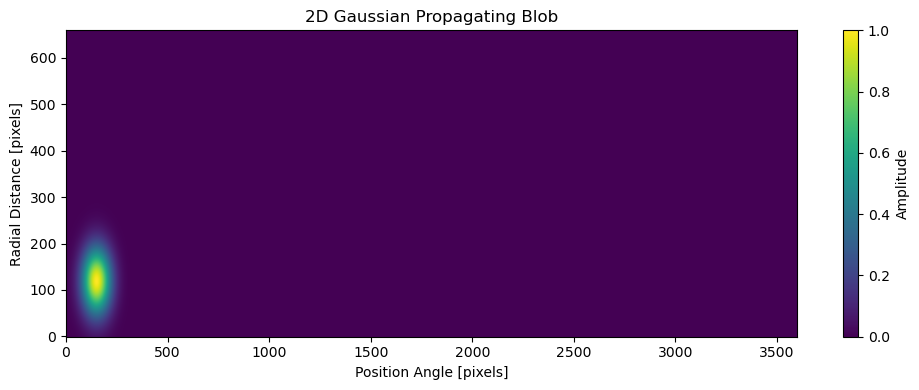

In [13]:
# Parameters for 2D Gaussian blob
npixel = [3600, 659]         # Image dimensions: [position angle, radial distance]
center = [150, 120]          # Center position of the Gaussian blob
st_dev = [50, 50]            # Standard deviation in each direction

# Generate the 2D Gaussian profile
blob = gaussian_wave(npixel, center, st_dev)

# Plot the result
plt.figure(figsize=(10, 4))
plt.imshow(blob.T, origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(label='Amplitude')
plt.title('2D Gaussian Propagating Blob')
plt.xlabel('Position Angle [pixels]')
plt.ylabel('Radial Distance [pixels]')
plt.tight_layout()
plt.show()

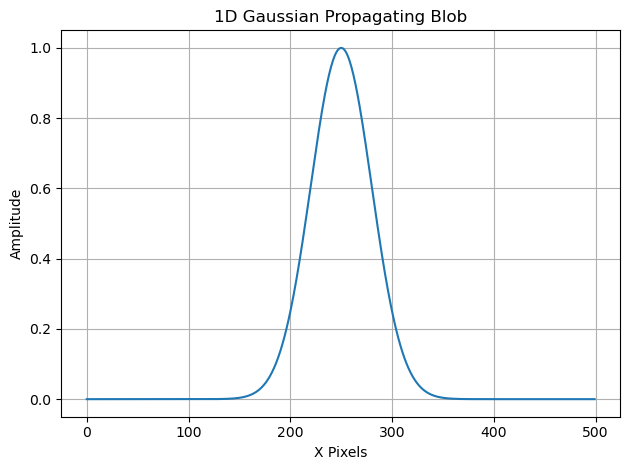

In [14]:
# Parameters for 1D Gaussian blob
npixel_1d = [500]            # Number of pixels along the x-axis
center_1d = [250]            # Center of the Gaussian
st_dev_1d = [30]             # Standard deviation

# Generate the 1D Gaussian profile
blob_1d = gaussian_wave(npixel_1d, center_1d, st_dev_1d)

# Plot the result
plt.figure()
plt.plot(blob_1d)
plt.title('1D Gaussian Propagating Blob')
plt.xlabel('X Pixels')
plt.ylabel('Amplitude')
plt.grid(True)
plt.tight_layout()
plt.show()

# Image Generation

The SYNCOM_IMAGE module creates 2D synthetic images of the solar wind by summing multiple Gaussian blobs distributed across position angles (θ) and radial distances (r).

## Inputs:
<ul> 
    <li><code>params</code>: Dictionary with simulation settings 
        (<code>syncom_nx</code>, <code>syncom_ny</code>, <code>syncom_n_blobs</code>)</li> 
    <li><code>syncom_version</code>: String label used to name output FITS files</li> 
    <li><code>time_0</code>: Initial time offset in frames</li> 
    <li><code>radial_i</code>: Array of initial radial positions for each blob [pixels]</li> 
    <li><code>v_array</code>: Array of radial velocities [pixels/frame]</li> 
    <li><code>period_array</code>: Array controlling the periodicity of blob reappearance [seconds]</li> 
    <li><code>L_array</code>: Blob width array [degrees], determines radial and angular size</li> 
    <li><code>PSI</code>: Central position angles (θ) for each blob [degrees]</li> 
    <li><code>time_t</code>: Current simulation time step [frames]</li> 
</ul>

### Description:

At each time step, the function computes the radial shift of each blob based on its velocity and time offset. A base 2D Gaussian is generated using gaussian_wave, centered at the blob's specified position and width.

To simulate quasiperiodic structures, six shifted copies of each blob (at ±2, ±4, ±6 × (period·v + L)) are added along the radial axis, giving 7 copies in total, as in IDL. The main Gaussian and its harmonics are then shifted according to the blob's current position.

All blobs are summed into a cumulative 2D array representing the full image of the synthetic solar wind outflow. This image is saved as a FITS file, preserving its resolution and enabling further analysis.

PS: The function is called by <code>SYNCOM_CORE</code> at every timestep from <code>t = 0</code> to <code>t = t_final</code>, capturing both fine- and large-scale transient solar wind dynamics.

<b>Implementation:</b> each blob is an angle profile times a radial profile, and all shifts act along the radius, so the image is computed as one matrix product over all blobs instead of a loop over full 2D arrays.

In [15]:
def _roll_rows(a, shifts):
    """
    Row-wise np.roll: rolls each row a[k] by its own shifts[k] along axis 1.
    Equivalent to np.stack([np.roll(a[k], shifts[k]) for k in range(len(a))]).
    """
    n = a.shape[1]
    idx = (np.arange(n)[None, :] - shifts[:, None]) % n
    return np.take_along_axis(a, idx, axis=1)


def syncom_image(params, syncom_version, time_0, radial_i, v_array,
                 period_array, L_array, PSI, time_t, save_fits=True, out_dir=".", chunk_size=500):
    """
    Generates a synthetic solar wind image at a given time step (IDL syncom_image.pro, vectorized).

    Parameters:
        params: dict with keys 'syncom_nx', 'syncom_ny', 'syncom_n_blobs'
        syncom_version: string identifier for simulation version
        time_0: initial time offset (in frames), scalar or per blob
        radial_i: array of initial radial positions [pixels]
        v_array: array of radial velocities [pixels/frame]
        period_array: array of blob periods [seconds]
        L_array: array of blob sizes [pixels]
        PSI: array of position angles [0.1 degree]
        time_t: current time step [frames]
        save_fits (bool): write SynCOM_<version>_<time_t>.fts (same layout as the IDL files)
        out_dir: folder for the FITS file
        chunk_size: blobs processed at once (limits memory use)

    Returns:
        img: 2D NumPy array [NX, NY] representing the synthetic image
    """
    start_time = time.time()

    n_blobs = int(params["syncom_n_blobs"])
    NX = int(params["syncom_nx"])
    NY = int(params["syncom_ny"])

    radial_t = (time_t + time_0) * v_array  # pixel positions at time_t

    PSI = np.asarray(PSI, dtype=float)[:n_blobs]
    radial_i = np.asarray(radial_i, dtype=float)[:n_blobs]
    L_array = np.asarray(L_array, dtype=float)[:n_blobs]
    period_array = np.asarray(period_array, dtype=float)[:n_blobs]
    v_array = np.asarray(v_array, dtype=float)[:n_blobs]
    radial_t = np.asarray(radial_t, dtype=float)[:n_blobs]

    x = np.arange(NX)
    y = np.arange(NY)
    img = np.zeros((NX, NY), dtype=float)

    for start in range(0, n_blobs, chunk_size):
        sl = slice(start, min(start + chunk_size, n_blobs))
        psi, r0, L = PSI[sl], radial_i[sl], L_array[sl]
        P, v = period_array[sl], v_array[sl]

        # Angular profile: centred at NX/2, then shifted (with wrap-around) to PSI
        gx = np.exp(-((x[None, :] - NX / 2.0)**2) / (2 * L[:, None]**2))
        gx = _roll_rows(gx, np.trunc(psi - NX / 2.0).astype(int))

        # Radial profile (st_dev = 2L)
        gy0 = np.exp(-((y[None, :] - r0[:, None])**2) / (2 * (2 * L[:, None])**2))

        # Add 6 shifted copies of the ORIGINAL blob (7 copies in total, as in IDL)
        gy = gy0.copy()
        for n in [2, 4, 6, -2, -4, -6]:
            gy += _roll_rows(gy0, np.trunc(n * P * v + n * L).astype(int))

        # Shift for radial displacement over time
        gy = _roll_rows(gy, np.trunc(radial_t[sl]).astype(int))

        # Sum of outer(gx_i, gy_i) over the blobs in this chunk
        img += gx.T @ gy

    if save_fits:
        filename = Path(out_dir) / f"SynCOM_{syncom_version}_{time_t}.fts"
        fits.writeto(filename, img.T, overwrite=True)   # .T -> same layout as IDL (NAXIS1 = NX)

    print(f"Run time for step {time_t}: {time.time() - start_time:.2f} s")

    return img

## Example: Creating a Synthetic Solar Image

This example demonstrates how to generate a synthetic solar wind image using the syncom_image function with mock or random input arrays. These values can be replaced with outputs from your own simulation pipeline.

In [16]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

def plot_syncom_image(img, title="SynCOM Synthetic Image", cmap='inferno'):
    """
    Plots the 2D synthetic solar wind image [NX, NY] with a tight colorbar.
    """
    fig, ax = plt.subplots(figsize=(12, 5))
    im = ax.imshow(img.T, origin='lower', aspect='auto', cmap=cmap)

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="2%", pad=0.15)

    cbar = plt.colorbar(im, cax=cax)
    cbar.set_label('Intensity')

    ax.set_title(title)
    ax.set_xlabel('Position Angle [0.1 degree pixels]')
    ax.set_ylabel('Radial Distance [pixels]')
    plt.tight_layout()
    plt.show()

Run time for step 0: 0.54 s


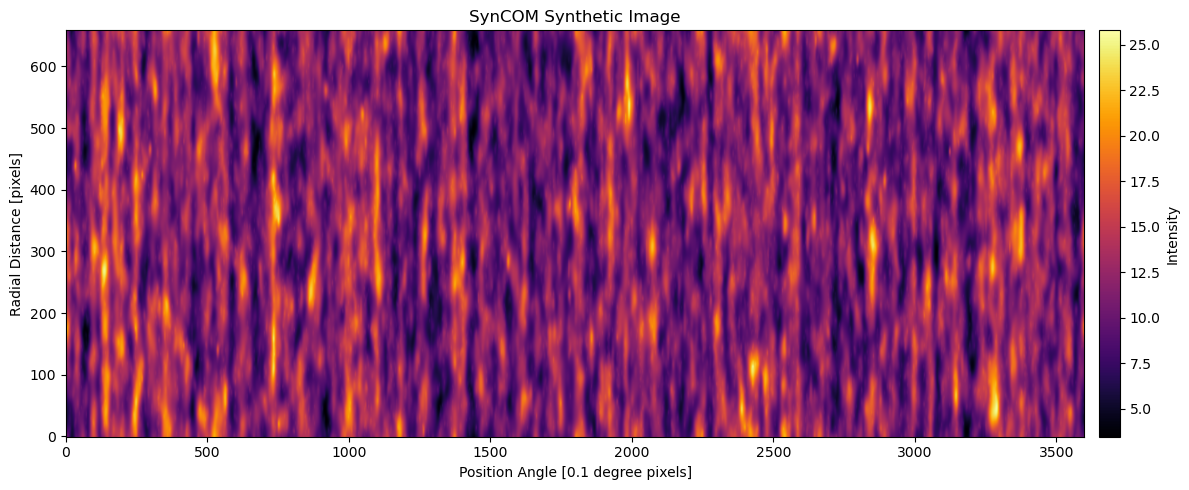

In [17]:
# Single image from the blobs generated above
radial_i, v_array, period_array, L_array, PSI = blob_arrays(load_struc["outarray"], params)
time_0 = np.random.default_rng(22).normal(size=params["syncom_n_blobs"]) * 200.0 + 1.0   # IDL: randomn*200 + 1

img = syncom_image(params, "v1", time_0, radial_i, v_array, period_array, L_array, PSI,
                   time_t=0, save_fits=False)
plot_syncom_image(img)

In [18]:
def syncom_core(
    N_BLOBS,
    time0,
    time_t,
    syncom_version="v1",
    scale_factor=None,
    simple=True,
    save=False,
    params=None,
    LoadStruc=None,
    time_0=None,
    freq_file=FREQ_FILE,
    idl_compat=True,
    save_fits=True,
    out_dir="."
):
    """
    Simulates the solar wind outflow using SynCOM and produces a time-dependent image cube
    (IDL syncom.pro).

    Parameters:
        N_BLOBS (int): Number of blobs to simulate
        time0 (int): Starting time step
        time_t (int): Ending time step (exclusive)
        syncom_version (str): Label used in output file names
        scale_factor (float): Blob size scaling factor
        simple (bool): Sinusoidal velocity profile if True, STEREO profile if False
        save (bool): Save the cube as a compressed .npz
        params (dict): Model parameters
        LoadStruc (dict): Precomputed blob data (e.g. from load_idl_run)
        time_0 (array): Per-blob start offsets [frames]. Default: randomn*200 + 1 as in IDL,
            drawn with NumPy (IDL's own random numbers cannot be reproduced in Python).
        freq_file, idl_compat: passed to syncom_load when LoadStruc is None
        save_fits (bool): Write one FITS file per frame, as IDL did
        out_dir: Folder for the FITS files

    Returns:
        syncom_data (np.ndarray): 3D synthetic image cube [NX, NY, time_t - time0]
    """
    start_time = time.time()

    if params is None:
        raise ValueError("params dictionary must be provided.")

    params["syncom_n_blobs"] = N_BLOBS
    nx = int(params["syncom_nx"])
    ny = int(params["syncom_ny"])
    scalefactor = scale_factor if scale_factor is not None else params["syncom_scale_factor"]
    params["syncom_scale_factor"] = scalefactor

    if LoadStruc is None:
        LoadStruc = syncom_load(params, simple=simple, freq_file=freq_file, idl_compat=idl_compat)

    radial_i, v_array, period_array, L_array, PSI = blob_arrays(LoadStruc["outarray"], params, scalefactor)

    if time_0 is None:
        time_0 = np.random.default_rng(22).normal(size=N_BLOBS) * 200.0 + 1.0

    nt = time_t - time0
    syncom_data = np.zeros((nx, ny, nt), dtype=float)

    for t in range(time0, time_t):
        syncom_data[:, :, t - time0] = syncom_image(
            params, syncom_version, time_0, radial_i, v_array, period_array, L_array, PSI, t,
            save_fits=save_fits, out_dir=out_dir)

    if save:
        output_name = f"SynCOM_{syncom_version}_cube.npz"
        np.savez_compressed(output_name, syncom_data=syncom_data, params=params,
                            LoadStruc=LoadStruc, scale_factor=scalefactor)
        print(f"✅ Saved: {output_name}")

    print(f"⏱️ Total runtime: {time.time() - start_time:.2f} s")
    return syncom_data

In [19]:
# Step 1: Load SynCOM parameters
params = default_syncom_prams(SYNCOM_N_BLOBS=5000, DATE="2023-04-11")

# Step 2: Run the simulation for 20 frames
cube = syncom_core(
    N_BLOBS=5000,           # Number of blobs
    time0=0,                # Starting time index
    time_t=20,              # Ending time index (exclusive)
    syncom_version="v1",    # Label for output files
    scale_factor=1.0,       # Blob size scaling
    simple=True,            # Sinusoidal velocity profile (as in the IDL "simple" runs)
    save=False,             # True -> save the cube as .npz
    save_fits=False,        # True -> one FITS file per frame, as IDL did
    params=params
)

Run time for step 0: 0.54 s


Run time for step 1: 0.54 s


Run time for step 2: 0.65 s


Run time for step 3: 0.76 s


Run time for step 4: 0.69 s


Run time for step 5: 0.74 s


... (10 outputs left out)

Run time for step 16: 0.71 s


Run time for step 17: 0.55 s


Run time for step 18: 0.54 s


Run time for step 19: 0.59 s
⏱️ Total runtime: 12.83 s


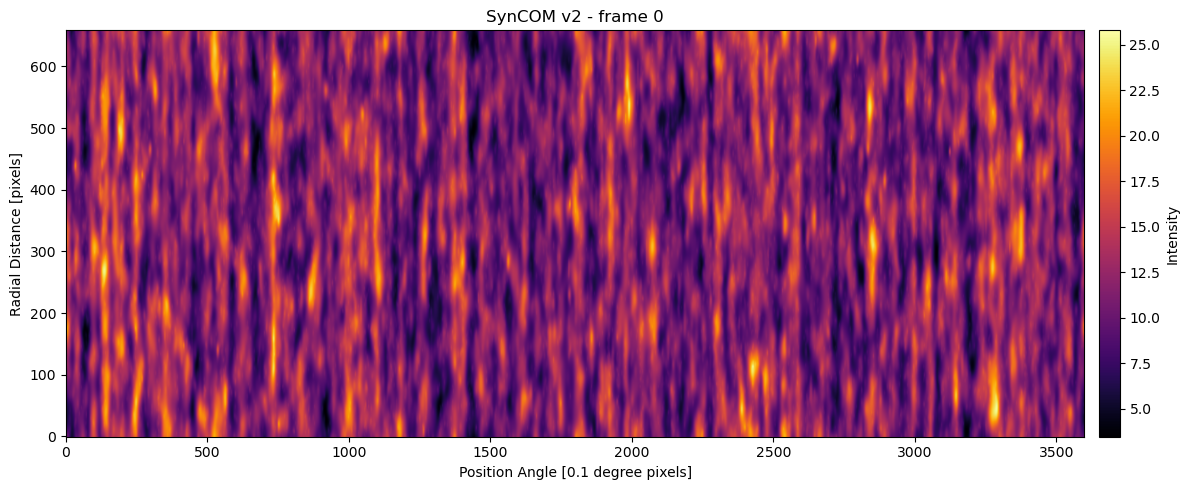

In [20]:
plot_syncom_image(cube[:, :, 0], title='SynCOM v2 - frame 0')

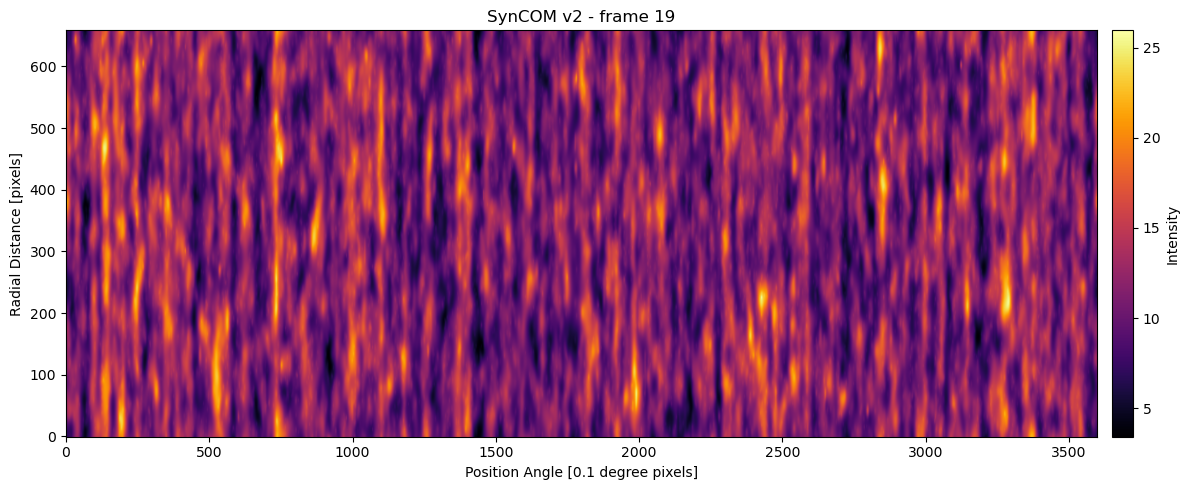

In [21]:
plot_syncom_image(cube[:, :, 19], title='SynCOM v2 - frame 19')

# Replaying an IDL run

<code>load_idl_run</code> reads the blob parameters (<code>LoadStruc</code>) and settings (<code>ModPramsStruct</code>) from an IDL <code>*_cube.sav</code>. It skips the multi-GB image cube, so it takes only seconds. With these, the notebook generates the same blobs as the IDL run.

<b>Validation without the start times:</b> IDL did not save the per-blob start offsets <code>time_0</code>. They only move each blob along the radius, with wrap-around, so the image summed over all radii (brightness vs position angle) does not depend on them. The next cells check that profile against an IDL FITS frame; it should agree to floating-point precision.

<b>Exact frame-by-frame replay:</b> <code>time_0</code> came from <code>randomn(22, n_blobs)*200. + 1</code> with a fixed seed, so IDL can regenerate it. In IDL, run
<pre>t0 = randomn(22, 5000)*200. + 1 &amp; save, t0, filename='time0.sav'</pre>
then set <code>IDL_TIME0_SAV</code> below to compare whole frames pixel by pixel.

In [22]:
def load_idl_run(cube_sav, max_elements=50_000_000):
    """
    Reads ModPramsStruct and LoadStruc from an IDL SynCOM *_cube.sav without loading the
    (multi-GB) syncom_data cube.

    Returns:
        params (dict): notebook-style parameters. syncom_scale_factor is taken from SYNCOM_SIZE;
            IDL passed scale_factor to SYNCOM separately, so override it if the run used another one.
        LoadStruc (dict): {'outarray': (n_blobs, 8) array, 'velocity': (3600,) array}
    """
    original = _idl._read_array

    def _skip_big_arrays(f, typecode, array_desc):
        if array_desc["nelements"] > max_elements:
            return None                       # readsav jumps to the next record afterwards
        return original(f, typecode, array_desc)

    _idl._read_array = _skip_big_arrays
    try:
        sav = _idl.readsav(str(cube_sav))
    finally:
        _idl._read_array = original

    mp = sav["modpramsstruct"]
    get = lambda key: mp[key][0]
    params = default_syncom_prams(
        SYNCOM_N_BLOBS=int(get("SYNCOM_N_BLOBS")),
        SYNCOM_CADENCE=float(get("SYNCOM_CADENCE")),
        SYNCOM_NX=int(get("SYNCOM_NX")),
        SYNCOM_NY=int(get("SYNCOM_NY")),
        SYNCOM_ACC=float(get("SYNCOM_ACC")),
        SYNCOM_TIME=float(get("SYNCOM_TIME")),
        SYNCOM_INITIAL_R_SUN=float(get("SYNCOM_INITIAL_R_SUN")),
        SYNCOM_SCALE_FACTOR=float(get("SYNCOM_SIZE")),
        SYNCOM_NOISE_LEVEL=float(get("SYNCOM_NOISE_LEVEL")),
        SYNCOM_MAX_INTENSITY=float(get("SYNCOM_MAX_INTENSITY")),
        SYNCOMFILE=get("FILENAME").decode(),
    )

    ls = sav["loadstruc"]
    LoadStruc = {
        "outarray": np.asarray(ls["OUTARRAY"][0]).T,   # IDL [n_blobs, 8] -> NumPy (n_blobs, 8)
        "velocity": np.asarray(ls["VELOCITY"][0]),
    }
    return params, LoadStruc


def idl_fits_frame(fits_dir, frame):
    """Returns the IDL FITS image for a frame number as an [NX, NY] array (matching syncom_image)."""
    for f in Path(fits_dir).glob("*.fts"):
        if f.name.startswith("._"):
            continue
        if float(f.stem.rsplit("_", 1)[-1]) == frame:
            return fits.getdata(f).T
    raise FileNotFoundError(f"No FITS file for frame {frame} in {fits_dir}")

/Users/valmirmoraesfilho/miniforge3/envs/syncom-punch/lib/python3.12/site-packages/scipy/io/_idl.py:338: UserWarning: Using experimental 64-bit array read
  rectypedesc = _read_typedesc(f)


{'syncom_n_blobs': 5000, 'syncom_initial_R_sun': 5.0, 'syncom_cadence': 300.0, 'syncom_scale_factor': 1.0}


Run time for step 0: 0.69 s
Radius-summed profile, Python vs IDL FITS: max relative difference = 2.61e-08
✅ Matches the IDL run


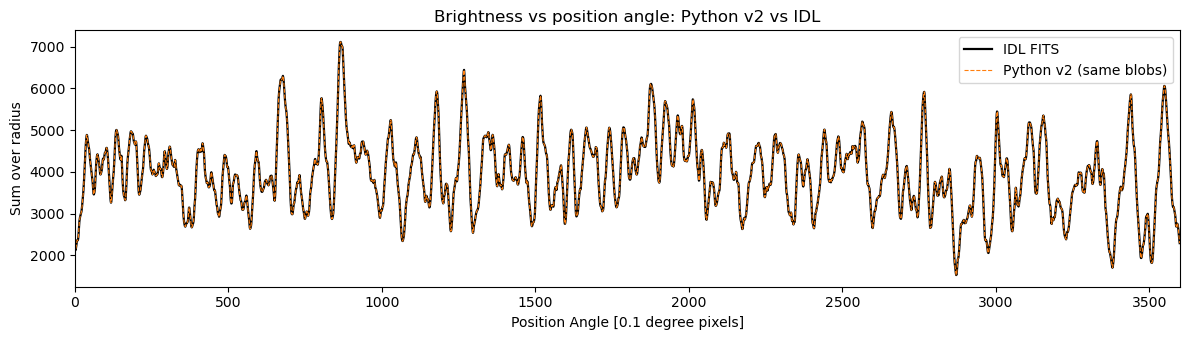

In [23]:
idl_params, idl_load = load_idl_run(IDL_CUBE_SAV)
print({k: idl_params[k] for k in ["syncom_n_blobs", "syncom_initial_R_sun", "syncom_cadence", "syncom_scale_factor"]})

radial_i, v_array, period_array, L_array, PSI = blob_arrays(idl_load["outarray"], idl_params)
n_idl = idl_params["syncom_n_blobs"]

# Any start times give the same radius-summed profile
t0_any = np.random.default_rng(22).normal(size=n_idl) * 200.0 + 1.0
img_py = syncom_image(idl_params, "replay", t0_any, radial_i, v_array, period_array, L_array, PSI,
                      time_t=0, save_fits=False)
img_idl = idl_fits_frame(IDL_FITS_DIR, 0)

prof_py, prof_idl = img_py.sum(axis=1), img_idl.sum(axis=1)
rel_diff = np.abs(prof_py - prof_idl).max() / prof_idl.max()
print(f"Radius-summed profile, Python vs IDL FITS: max relative difference = {rel_diff:.2e}")
assert rel_diff < 1e-6, "Python and IDL disagree - check scale_factor and the IDL run settings"
print("✅ Matches the IDL run")

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(prof_idl, color="k", lw=1.6, label="IDL FITS")
ax.plot(prof_py, color="tab:orange", lw=0.8, ls="--", label="Python v2 (same blobs)")
ax.set_xlim(0, idl_params["syncom_nx"])
ax.set_xlabel("Position Angle [0.1 degree pixels]")
ax.set_ylabel("Sum over radius")
ax.set_title("Brightness vs position angle: Python v2 vs IDL")
ax.legend()
plt.tight_layout()
plt.show()

IDL FITS frame 0         mean 5.998   std/mean 0.350
Python v2, same blobs    mean 5.998   std/mean 0.349


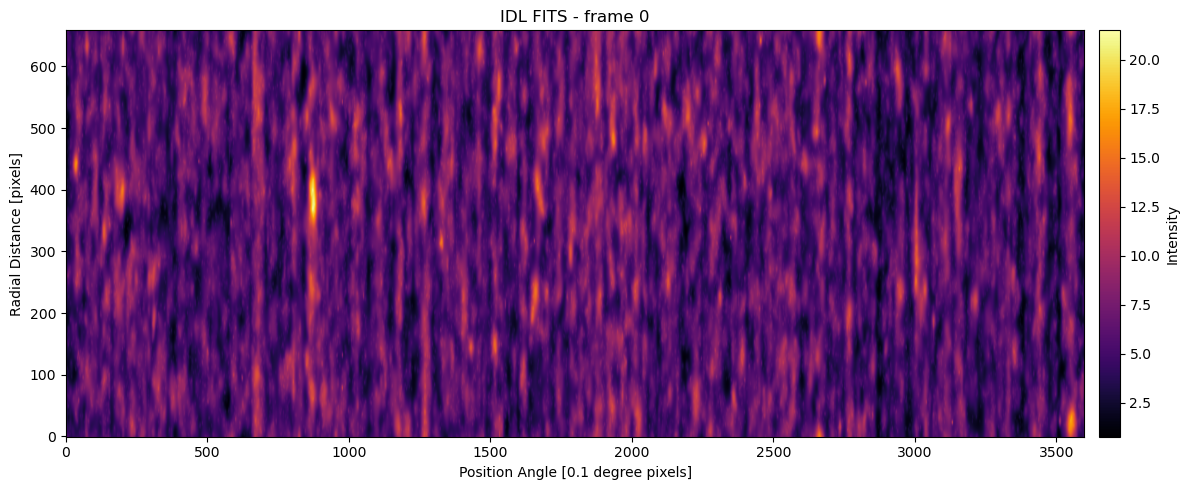

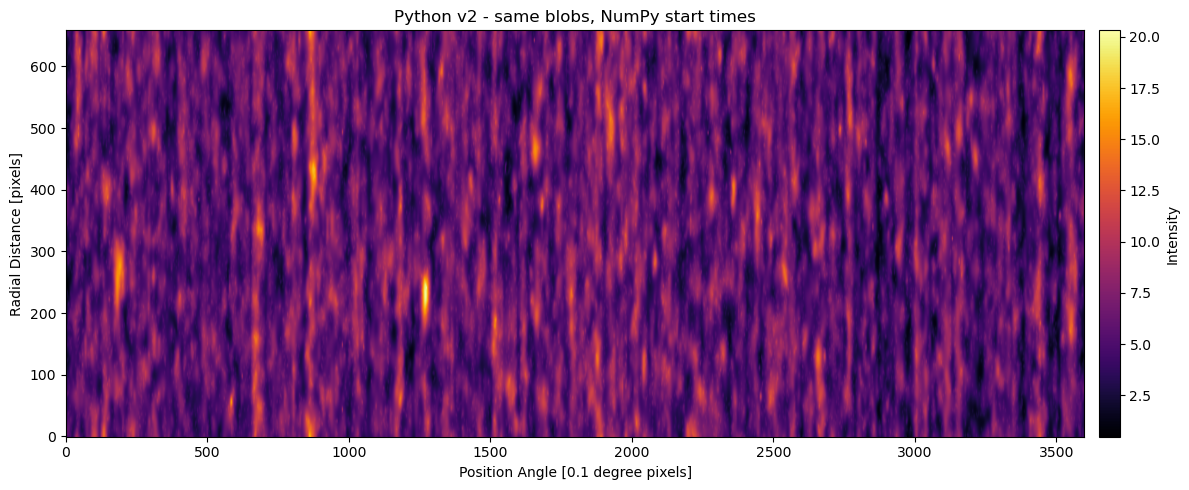

In [24]:
# Frame comparison. Without IDL's time_0 the blobs sit at different radii, so frames should look
# statistically alike rather than identical.
for name, im in [("IDL FITS frame 0", img_idl), ("Python v2, same blobs", img_py)]:
    print(f"{name:24s} mean {im.mean():.3f}   std/mean {im.std() / im.mean():.3f}")
plot_syncom_image(img_idl, title="IDL FITS - frame 0")
plot_syncom_image(img_py, title="Python v2 - same blobs, NumPy start times")

In [25]:
# Exact replay: set this to a time0.sav exported from IDL (see the note above)
IDL_TIME0_SAV = None   # e.g. IDL_RUN_DIR / "time0.sav"

if IDL_TIME0_SAV is not None and Path(IDL_TIME0_SAV).exists():
    t0_idl = np.asarray(readsav(str(IDL_TIME0_SAV))["t0"], dtype=float)
    for frame in [0, 100, 400]:
        img_py = syncom_image(idl_params, "replay", t0_idl, radial_i, v_array, period_array, L_array, PSI,
                              time_t=frame, save_fits=False)
        img_idl = idl_fits_frame(IDL_FITS_DIR, frame)
        print(f"frame {frame}: max relative difference = {np.abs(img_py - img_idl).max() / img_idl.max():.2e}")
else:
    print("IDL_TIME0_SAV not set - skipping the frame-by-frame comparison")

IDL_TIME0_SAV not set - skipping the frame-by-frame comparison


# Movie Output

The <code>save_syncom_movie</code> function turns the 3D cube returned by <code>syncom_core</code> (shape <code>[NX, NY, NT]</code>) into an MP4 video, one frame per time step, so you can watch the blobs propagate outward.

<ul>
<li><code>fps</code>: Playback speed (frames per second)</li>
<li><code>vmin</code>, <code>vmax</code>: Color limits, held fixed for every frame so the brightness does not flicker (default: 1st–99.5th percentile of the whole cube)</li>
<li><code>cadence</code>: Seconds between frames; if given, the elapsed time is printed in each frame's title</li>
<li><code>extent</code>: Optional physical axis limits <code>[x0, x1, y0, y1]</code>; otherwise axes are in pixels</li>
</ul>

Requires <code>ffmpeg</code> (<code>conda install -c conda-forge ffmpeg</code>).

In [26]:
import shutil
from matplotlib import animation
from mpl_toolkits.axes_grid1 import make_axes_locatable


def save_syncom_movie(cube, filename="SynCOM_movie.mp4", fps=10, cmap="inferno",
                      vmin=None, vmax=None, cadence=None, extent=None,
                      title="SynCOM Synthetic Image", figsize=(12, 5), dpi=100):
    """
    Saves a SynCOM data cube as an MP4 video, one frame per time step.

    Parameters:
        cube (np.ndarray): 3D image cube [NX, NY, NT] (output of syncom_core)
        filename (str): Output .mp4 path
        fps (int): Frames per second of the video
        cmap (str): Matplotlib colormap
        vmin, vmax (float): Fixed color limits for every frame. If None, they are
            taken from the 1st and 99.5th percentiles of the whole cube, so the
            brightness scale does not flicker between frames.
        cadence (float): Seconds between frames (e.g. params["syncom_cadence"]).
            If given, the elapsed time is shown in each frame's title.
        extent (list): [x0, x1, y0, y1] physical axis limits, e.g.
            [0, 360, r_min, r_max]. If None, axes are in pixels.
        title (str): Base title shown on every frame
        figsize (tuple): Figure size in inches
        dpi (int): Resolution of the video frames

    Returns:
        Path: Path to the saved MP4 file
    """
    cube = np.asarray(cube)
    if cube.ndim != 3:
        raise ValueError(f"cube must be 3D [NX, NY, NT], got shape {cube.shape}")
    if shutil.which("ffmpeg") is None:
        raise RuntimeError("ffmpeg not found. Install it with: conda install -c conda-forge ffmpeg")

    nt = cube.shape[2]

    # Fixed color scale for the whole movie (subsampled to keep it fast on big cubes)
    if vmin is None or vmax is None:
        lo, hi = np.nanpercentile(cube[::4, ::4, :], [1, 99.5])
        vmin = lo if vmin is None else vmin
        vmax = hi if vmax is None else vmax

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(cube[:, :, 0].T, origin='lower', aspect='auto', cmap=cmap,
                   vmin=vmin, vmax=vmax, extent=extent)

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="2%", pad=0.15)
    cbar = plt.colorbar(im, cax=cax)
    cbar.set_label('Intensity')

    if extent is None:
        ax.set_xlabel('Position Angle [pixels]')
        ax.set_ylabel('Radial Distance [pixels]')
    else:
        ax.set_xlabel('Position Angle [degrees]')
        ax.set_ylabel('Radial Distance [Solar Radii]')

    def frame_title(i):
        if cadence is not None:
            return f"{title}  |  t = {i * cadence / 3600:.2f} h  (frame {i + 1}/{nt})"
        return f"{title}  |  frame {i + 1}/{nt}"

    ax.set_title(frame_title(0))
    fig.tight_layout()

    # yuv420p + even dimensions -> plays in QuickTime, browsers, PowerPoint, etc.
    writer = animation.FFMpegWriter(
        fps=fps, codec="libx264",
        extra_args=["-pix_fmt", "yuv420p", "-vf", "scale=trunc(iw/2)*2:trunc(ih/2)*2"]
    )

    filename = Path(filename)
    with writer.saving(fig, str(filename), dpi=dpi):
        for i in range(nt):
            im.set_data(cube[:, :, i].T)
            ax.set_title(frame_title(i))
            writer.grab_frame()

    plt.close(fig)
    print(f"✅ Saved movie: {filename} ({nt} frames at {fps} fps)")
    return filename

In [27]:
# Save the simulated cube as an MP4 movie
save_syncom_movie(
    cube,
    filename="SynCOM_v2_movie.mp4",
    fps=5,                              # 20 frames -> 4 s video
    cadence=params["syncom_cadence"],   # show elapsed time in the title
)

✅ Saved movie: SynCOM_v2_movie.mp4 (20 frames at 5 fps)


PosixPath('SynCOM_v2_movie.mp4')